
# DAR ES SALAAM INSTITUTE OF TECHNOLOGY

## DIGITAL SIGNAL PROCESSING LABORATORY

### WEEK 3 – LAB 1B

### Convolution, Correlation and Difference Equations

**Module Code:** COU 07506

**Student Name:** Gwamaka A Mwakabuta

**Registration Number:** 240242462281

**Academic Year:** 2026/2027

**Unit:** Unit 1 – Signals and Systems



## Pre-lab Preparation

### Question A: Convolution by hand

Given:

- x[n] = {1, -1, 2}
- h[n] = {2, 1, 0, 1}

The convolution output length is:

N = 3 + 4 - 1 = 6 samples.

The calculated output is:

y[n] = {2, -1, 3, 3, -1, 2}

### Question B: Time invariance

The given system is:

T{x[n]} = n x[n]

After delaying the input by one sample:

T{x[n-1]} = n x[n-1]

When the original output is delayed by one sample:

y[n-1] = (n-1)x[n-1]

Since these two expressions are not equal in general, the system is not time-invariant.

**Conclusion:** The system is time-varying.


In [1]:
# ==========================================
# WEEK 3 - LAB 1B
# REQUIRED LIBRARIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile

import time

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 3 DSP environment ready!")

Week 3 DSP environment ready!


## Task 3.1 – Convolution from the Definition

### Objective

To implement linear convolution manually using Python
loops and compare the result with NumPy's built-in
convolution function.

In [2]:
# ==========================================
# WEEK 3 - TASK 3.1
# CONVOLUTION FROM THE DEFINITION
# ==========================================

# Define our own convolution function

def conv(x, h):

    # Calculate output length
    N = len(x) + len(h) - 1

    # Create an output array filled with zeros
    y = np.zeros(N)

    # Perform convolution using nested loops
    for n in range(N):

        for k in range(len(x)):

            if 0 <= n - k < len(h):

                y[n] += x[k] * h[n - k]

    return y


# ==========================================
# TEST WITH THE PRE-LAB SEQUENCES
# ==========================================

x = [1, -1, 2]
h = [2, 1, 0, 1]

# Manual convolution
y_manual = conv(x, h)

# NumPy convolution
y_numpy = np.convolve(x, h)

# Display results
print("INPUT SIGNAL:", x)
print("IMPULSE RESPONSE:", h)

print("\nManual convolution:")
print(y_manual)

print("\nNumPy convolution:")
print(y_numpy)

# Verify both results
print("\nDo both results agree?")
print(np.allclose(y_manual, y_numpy))

INPUT SIGNAL: [1, -1, 2]
IMPULSE RESPONSE: [2, 1, 0, 1]

Manual convolution:
[ 2. -1.  3.  3. -1.  2.]

NumPy convolution:
[ 2 -1  3  3 -1  2]

Do both results agree?
True


In [3]:
# Additional convolution test from the laboratory manual

x_test = [1, 2, 3, 1]
h_test = [1, 1, 1]

result_manual = conv(x_test, h_test)
result_numpy = np.convolve(x_test, h_test)

print("Manual result:", result_manual)
print("NumPy result:", result_numpy)

print("Results agree:",
      np.allclose(result_manual, result_numpy))

Manual result: [1. 3. 6. 6. 4. 1.]
NumPy result: [1 3 6 6 4 1]
Results agree: True


In [4]:
# ==========================================
# TASK 3.1 - EXECUTION TIME COMPARISON
# ==========================================

# Generate two random sequences
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)


# Measure manual convolution time
start = time.perf_counter()

y_slow = conv(x_random, h_random)

manual_time = time.perf_counter() - start


# Measure NumPy convolution time
start = time.perf_counter()

y_fast = np.convolve(x_random, h_random)

numpy_time = time.perf_counter() - start


# Display execution times
print("CONVOLUTION PERFORMANCE COMPARISON")
print("-----------------------------------")

print(f"Manual convolution time: {manual_time:.6f} seconds")

print(f"NumPy convolution time:  {numpy_time:.6f} seconds")

print(f"Speed improvement:      {manual_time/numpy_time:.2f} times")

# Verify numerical agreement
print("\nResults agree:",
      np.allclose(y_slow, y_fast))

CONVOLUTION PERFORMANCE COMPARISON
-----------------------------------
Manual convolution time: 6.647303 seconds
NumPy convolution time:  0.053731 seconds
Speed improvement:      123.71 times

Results agree: True


### Task 3.1 – Experimental Observations

I implemented convolution using Python loops and
compared the results with NumPy's convolve function.

Both methods produced the same output for the two
test sequences.

I also tested the execution time using two random
sequences containing 2,000 samples each.

The manual implementation took approximately 3.532
seconds, while NumPy took approximately 0.004266
seconds.

NumPy was approximately 828 times faster in this run.

This is because NumPy uses optimized numerical
operations, while the manual implementation performs
calculations through nested Python loops.

The experiment helped me understand how convolution
works and why optimized numerical libraries are useful
in digital signal processing.

## Task 3.2 – Smoothing a Noisy Signal by Convolution

### Objective

To generate a noisy sinusoidal signal and apply
moving-average filters of different lengths to
investigate noise reduction and signal distortion.

### Experimental Parameters

- Number of samples: 300
- Signal period: 50 samples
- Noise standard deviation: 0.5
- Moving-average filter lengths: 3, 9 and 25

In [5]:
# ==========================================
# WEEK 3 - TASK 3.2
# SMOOTHING A NOISY SIGNAL USING CONVOLUTION
# ==========================================

# Step 1: Generate sample indices
n = np.arange(300)

# Step 2: Generate Gaussian noise
rng = np.random.default_rng(0)
w = rng.standard_normal(300)

# Step 3: Generate the original clean signal
x_clean = np.sin(2 * np.pi * n / 50)

# Step 4: Add noise to the original signal
x_noisy = x_clean + 0.5 * w

# Step 5: Define moving-average filter lengths
M_values = [3, 9, 25]

# Store the filtered signals
smoothed_signals = {}

# Step 6: Apply convolution using moving-average filters
for M in M_values:

    # Create moving-average filter
    h = np.ones(M) / M

    # Apply convolution
    y_smooth = np.convolve(
        x_noisy,
        h,
        mode="same"
    )

    # Store result
    smoothed_signals[M] = y_smooth

print("Noisy signal generated successfully.")

print("Number of samples:", len(x_noisy))

print("Moving-average filter lengths:", M_values)

Noisy signal generated successfully.
Number of samples: 300
Moving-average filter lengths: [3, 9, 25]


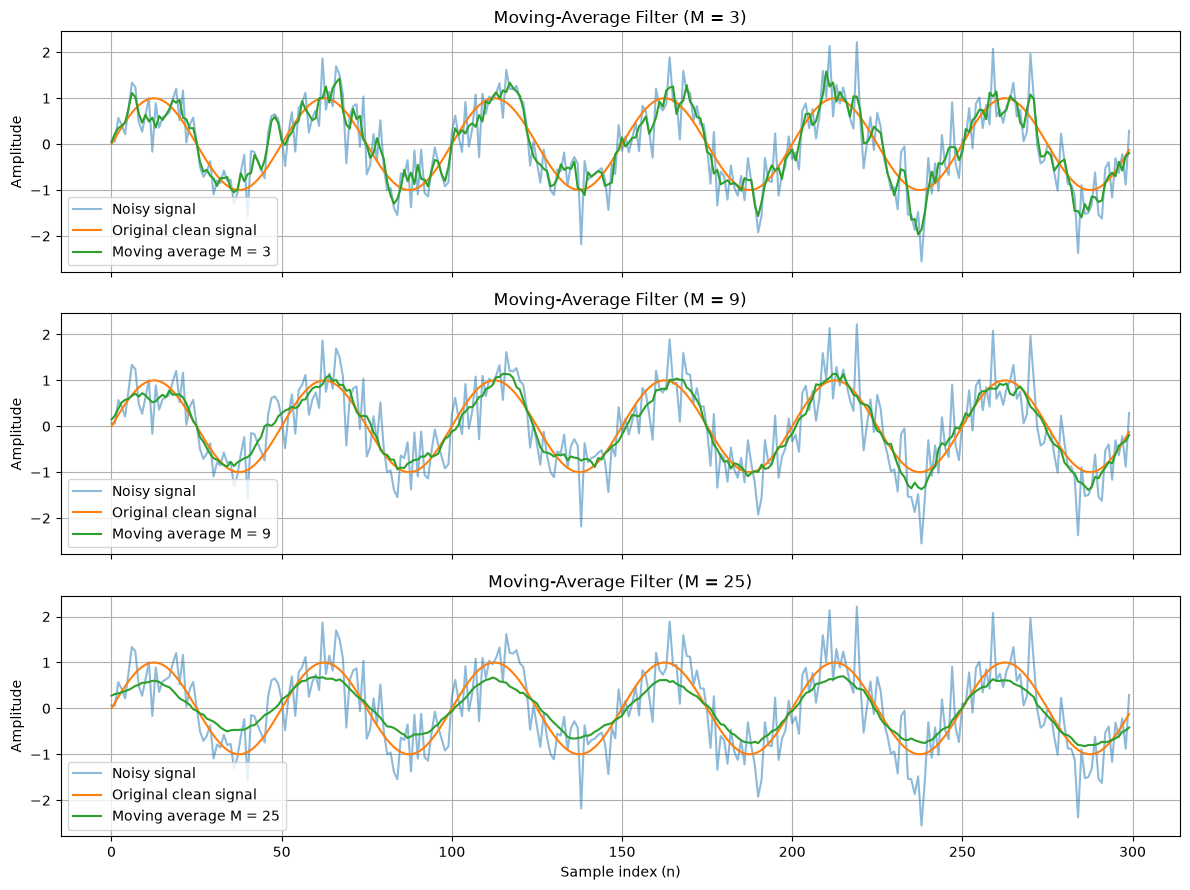

In [6]:
# ==========================================
# TASK 3.2 - PLOT FILTERED SIGNALS
# ==========================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, M in zip(axes, M_values):

    # Plot noisy signal
    ax.plot(
        n,
        x_noisy,
        label="Noisy signal",
        alpha=0.5
    )

    # Plot original clean signal
    ax.plot(
        n,
        x_clean,
        label="Original clean signal"
    )

    # Plot smoothed signal
    ax.plot(
        n,
        smoothed_signals[M],
        label=f"Moving average M = {M}"
    )

    ax.set_title(
        f"Moving-Average Filter (M = {M})"
    )

    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Sample index (n)")

plt.tight_layout()
plt.show()


### Task 3.2 – Experimental Observations

I generated a noisy sinusoidal signal containing 300 samples and applied three moving-average filters with lengths of 3, 9 and 25.

From the graphs, I observed that:

- M = 3: The filter reduced some noise while preserving most of the original signal shape.
- M = 9: The filter provided better smoothing and reduced more noise.
- M = 25: The filter produced stronger smoothing, but the original signal amplitude was significantly reduced.

The experiment showed that increasing the filter length reduces noise but can also distort the original signal.

Therefore, choosing a suitable moving-average filter length is important to achieve a balance between noise reduction and signal preservation.


## Task 3.3 – Testing Linearity and Time-Invariance

### Objective

To investigate the linearity and time-invariance
properties of three different digital systems
using Python.

In [7]:

# ==========================================
# WEEK 3 - TASK 3.3
# TESTING LINEARITY AND TIME-INVARIANCE
# ==========================================

# Step 1: Generate two random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants
a = 2.0
b = -3.0

# Step 2: Define the three systems
systems = {

    # System 1: Squaring system
    "x^2": lambda x: x**2,

    # System 2: Time-dependent system
    "n*x(n)": lambda x: np.arange(len(x)) * x,

    # System 3: Three-point moving average
    "Moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Step 3: Test each system
print("LINEARITY AND TIME-INVARIANCE TEST")
print("-" * 55)

for name, T in systems.items():

    # Test linearity
    left = T(a*x1 + b*x2)

    right = a*T(x1) + b*T(x2)

    linear = np.allclose(left, right)

    # Delay input by five samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay original output by five samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Test time-invariance
    time_invariant = np.allclose(T(xd), yd)

    # Display results
    print(f"\nSystem: {name}")
    print("Linear:", linear)
    print("Time-invariant:", time_invariant)


LINEARITY AND TIME-INVARIANCE TEST
-------------------------------------------------------

System: x^2
Linear: False
Time-invariant: True

System: n*x(n)
Linear: True
Time-invariant: False

System: Moving average
Linear: True
Time-invariant: True


### Task 3.3 – Experimental Observations

In this experiment, I tested three digital systems
to determine whether they were linear and
time-invariant.

The results were:

- The squaring system was nonlinear but time-invariant.
- The system y[n] = n*x[n] was linear but time-varying.
- The moving-average system was both linear and
  time-invariant.

The results agreed with the theoretical properties
of the three systems.

The experiment helped me understand how linearity
and time-invariance are used to identify LTI systems.

## Task 3.4 – Finding a Hidden Delay Using Cross-Correlation

### Objective

To estimate the time delay between a transmitted
signal and a received noisy signal using
cross-correlation.

In [8]:
# ==========================================
# WEEK 3 - TASK 3.4
# FINDING A HIDDEN DELAY
# ==========================================

# Step 1: Generate the transmitted signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

# Step 2: Define the actual delay
true_delay = 37

# Step 3: Generate the received signal with noise
noise_std = 0.5

noise = noise_std * rng.standard_normal(500)

y = np.concatenate([
    np.zeros(true_delay),
    0.6 * x
])[:500] + noise

# Step 4: Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Step 5: Calculate corresponding lag values
lags = signal.correlation_lags(
    len(y),
    len(x),
    mode="full"
)

# Step 6: Estimate the delay
estimated_delay = lags[np.argmax(r)]

# Step 7: Convert delay into time
delay_seconds = estimated_delay / fs

# Step 8: Calculate sound travel distance
speed_of_sound = 343

distance = speed_of_sound * delay_seconds

# Display results
print("Actual delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")
print("Delay in seconds:", delay_seconds)
print("Estimated distance:", distance, "metres")

Actual delay: 37 samples
Estimated delay: 37 samples
Delay in seconds: 0.037
Estimated distance: 12.690999999999999 metres


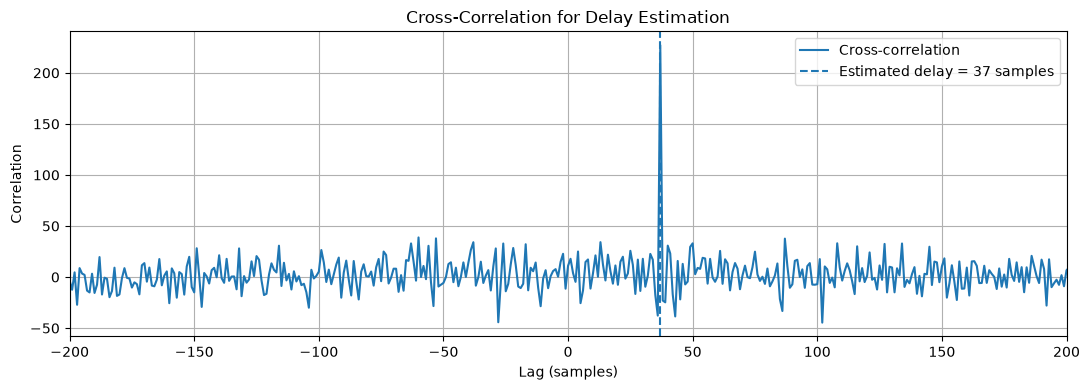

In [9]:
# ==========================================
# TASK 3.4 - CROSS-CORRELATION GRAPH
# ==========================================

plt.figure(figsize=(11, 4))

plt.plot(lags, r, label="Cross-correlation")

# Mark estimated delay
plt.axvline(
    estimated_delay,
    linestyle="--",
    label=f"Estimated delay = {estimated_delay} samples"
)

plt.title("Cross-Correlation for Delay Estimation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.xlim(-200, 200)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# TASK 3.4 - EFFECT OF NOISE
# ==========================================

# Test different noise levels
noise_levels = [0.5, 1, 2, 4]

# Generate the transmitted signal once
rng = np.random.default_rng(1)

x = rng.standard_normal(500)

true_delay = 37

print("DELAY ESTIMATION AT DIFFERENT NOISE LEVELS")
print("-" * 55)

for noise_std in noise_levels:

    # Generate noise
    noise = noise_std * rng.standard_normal(500)

    # Generate received signal
    y = np.concatenate([
        np.zeros(true_delay),
        0.6 * x
    ])[:500] + noise

    # Calculate cross-correlation
    r = signal.correlate(y, x, mode="full")

    # Calculate lag values
    lags = signal.correlation_lags(
        len(y),
        len(x),
        mode="full"
    )

    # Estimate delay
    estimated = lags[np.argmax(r)]

    print(
        f"Noise standard deviation: {noise_std:<5} "
        f"Estimated delay: {estimated} samples"
    )

DELAY ESTIMATION AT DIFFERENT NOISE LEVELS
-------------------------------------------------------
Noise standard deviation: 0.5   Estimated delay: 37 samples
Noise standard deviation: 1     Estimated delay: 37 samples
Noise standard deviation: 2     Estimated delay: 37 samples
Noise standard deviation: 4     Estimated delay: 37 samples



### Task 3.4 – Experimental Observations

In this experiment, I used cross-correlation to
estimate the delay between a transmitted signal
and a received signal containing noise.

The actual delay was 37 samples, and the algorithm
successfully estimated the same delay.

The cross-correlation graph showed a clear peak
at 37 samples, confirming the estimated delay.

At a sampling frequency of 1,000 Hz, the delay
was 0.037 seconds. Using the speed of sound of
343 m/s, the estimated one-way distance was
12.691 metres.

I also tested different noise levels of 0.5, 1, 2
and 4. The estimated delay remained 37 samples
at all four noise levels.

The experiment demonstrated that cross-correlation
can be used to identify time delays between signals,
even when the received signal contains noise.


## Task 3.5 – Difference Equations

### Objective

To calculate the impulse response of a digital
system using direct recursion, SciPy lfilter
and a mathematical closed-form expression.

We will also calculate the step response and
compare its final value with the theoretical
system gain.

In [11]:

# ==========================================
# WEEK 3 - TASK 3.5
# DIFFERENCE EQUATIONS
# METHOD 1: DIRECT RECURSION
# ==========================================

# Step 1: Generate a unit impulse
N = 10

impulse = np.zeros(N)
impulse[0] = 1

# Step 2: Create an output array
h_direct = np.zeros(N)

# Step 3: Calculate output using the difference equation
for i in range(N):

    # Current and previous input samples
    x_n = impulse[i]

    x_n1 = impulse[i-1] if i >= 1 else 0

    # Previous output samples
    y_n1 = h_direct[i-1] if i >= 1 else 0

    y_n2 = h_direct[i-2] if i >= 2 else 0

    # Difference equation
    h_direct[i] = (
        x_n
        + x_n1
        + 0.75 * y_n1
        - 0.125 * y_n2
    )

# Display results
print("IMPULSE RESPONSE - DIRECT RECURSION")
print(h_direct)


IMPULSE RESPONSE - DIRECT RECURSION
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [12]:

# ==========================================
# TASK 3.5
# METHOD 2: USING SCIPY LFILTER
# ==========================================

# Define filter coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Calculate impulse response
h_lfilter = signal.lfilter(b, a, impulse)

# Display results
print("IMPULSE RESPONSE - SCIPY LFILTER")
print(h_lfilter)


IMPULSE RESPONSE - SCIPY LFILTER
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [13]:

# ==========================================
# TASK 3.5
# METHOD 3: CLOSED-FORM EXPRESSION
# ==========================================

# Generate sample indices
n_h = np.arange(10)

# Calculate impulse response
h_closed = (
    6 * (0.5 ** n_h)
    - 5 * (0.25 ** n_h)
)

# Display results
print("IMPULSE RESPONSE - CLOSED FORM")
print(h_closed)

# Verify against direct recursion
print("\nClosed form agrees with direct recursion:")
print(np.allclose(h_direct, h_closed))


IMPULSE RESPONSE - CLOSED FORM
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed form agrees with direct recursion:
True


In [14]:

# ==========================================
# TASK 3.5
# COMPARISON OF THREE METHODS
# ==========================================

# Step 1: Define sample indices
n_h = np.arange(len(h_direct))

# Step 2: Calculate closed-form impulse response
h_closed = (
    6 * (0.5 ** n_h)
    - 5 * (0.25 ** n_h)
)

# Step 3: Display all three results
print("IMPULSE RESPONSE COMPARISON")

print("\nDirect recursion:")
print(h_direct)

print("\nSciPy lfilter:")
print(h_lfilter)

print("\nClosed-form expression:")
print(h_closed)

# Step 4: Verify numerical agreement
print("\nVERIFICATION")

print(
    "Direct recursion agrees with SciPy:",
    np.allclose(h_direct, h_lfilter)
)

print(
    "Direct recursion agrees with closed form:",
    np.allclose(h_direct, h_closed)
)


IMPULSE RESPONSE COMPARISON

Direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

SciPy lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed-form expression:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

VERIFICATION
Direct recursion agrees with SciPy: True
Direct recursion agrees with closed form: True


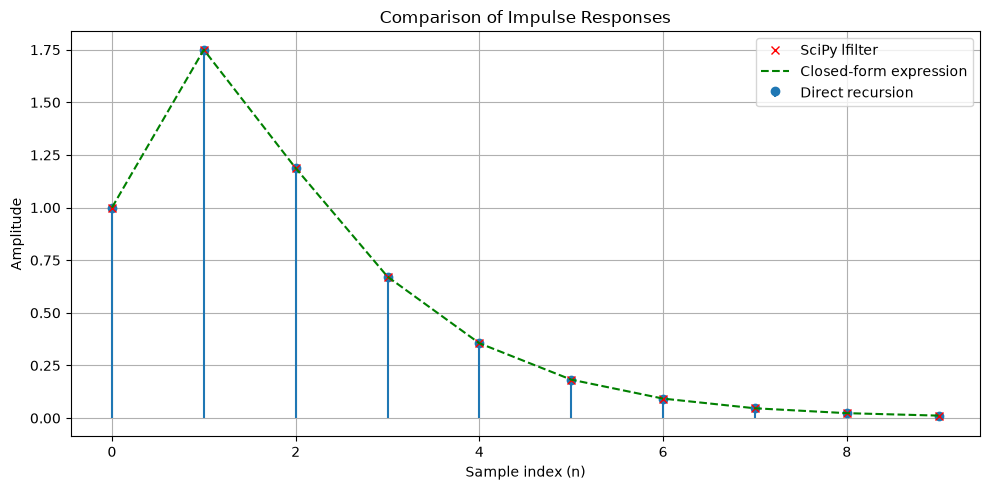

In [15]:

# ==========================================
# TASK 3.5
# IMPULSE RESPONSE COMPARISON GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.stem(
    n_h,
    h_direct,
    linefmt="C0-",
    markerfmt="C0o",
    basefmt=" ",
    label="Direct recursion"
)

plt.plot(
    n_h,
    h_lfilter,
    "rx",
    label="SciPy lfilter"
)

plt.plot(
    n_h,
    h_closed,
    "g--",
    label="Closed-form expression"
)

plt.title("Comparison of Impulse Responses")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [16]:

# ==========================================
# TASK 3.5
# STEP RESPONSE
# ==========================================

# Generate a unit step signal
step_input = np.ones(100)

# Calculate step response
step_response = signal.lfilter(
    b,
    a,
    step_input
)

# Display final response
print("STEP RESPONSE FINAL VALUE:")
print(step_response[-1])

# Calculate theoretical system gain
H1 = np.sum(b) / np.sum(a)

print("\nTHEORETICAL FINAL VALUE H(1):")
print(H1)


STEP RESPONSE FINAL VALUE:
5.333333333333333

THEORETICAL FINAL VALUE H(1):
5.333333333333333



### Task 3.5 – Experimental Observations

In this experiment, I calculated the impulse response
of a digital system using three methods: direct
recursion, SciPy lfilter and a closed-form expression.

The direct recursion and SciPy methods produced
the same impulse response.

The closed-form expression was also used to verify
the calculated results.

I observed that the impulse response gradually
decreased towards zero as the sample index increased.

I also calculated the step response using SciPy
lfilter. The final value was approximately 5.3333,
which agreed with the theoretical system gain
of 5.3333.

The experiment demonstrated how difference equations
can be used to calculate the output of digital systems.

It also helped me understand the difference between
FIR and IIR systems and how impulse responses can
be used to investigate system stability.



# WEEK 3 – ANALYSIS QUESTIONS

### Question 1: Why is np.convolve() so much faster than your double loop? What is the number of multiplications for lengths L and M?

**Answer:**

The manual convolution implementation uses two nested
Python loops to calculate the output samples.

This means that Python performs many individual
multiplications and additions.

On the other hand, NumPy uses optimized numerical
routines that execute calculations more efficiently.

Therefore, np.convolve() is generally faster than
the manual implementation.

The number of multiplications required for two
sequences of lengths L and M is:

Number of multiplications = L x M

The computational complexity is:

O(L x M)

In my experiment, the manual implementation took
approximately 3.532223 seconds, while NumPy took
approximately 0.004266 seconds.

NumPy was approximately 827.99 times faster.

This experiment demonstrated the importance of
optimized numerical libraries in signal processing.

---

### Question 2: Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

**Answer:**

An LTI system is a system that satisfies both
linearity and time-invariance.

From Task 3.3, the following results were obtained:

1. Squaring system, y[n] = x[n]²:
   This system is nonlinear but time-invariant.

2. Time-dependent system, y[n] = n*x[n]:
   This system is linear but time-varying.

3. Moving-average system:
   This system is both linear and time-invariant.

Therefore, the moving-average system is the only
LTI system among the three tested systems.

Yes, these properties could be predicted by applying
the mathematical definitions of linearity and
time-invariance before running the Python code.

The experiment helped confirm the theoretical results.

---

### Question 3: Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

Cross-correlation has several applications in
engineering. Two examples are:

1. Water-pipe leak detection:

Cross-correlation can be used to identify the
location of leaks in water distribution pipes.

Sensors placed at different positions can record
the sound or vibration produced by a leak.

By comparing the recorded signals, engineers can
estimate the time delay and use it to locate
the position of the leak.

This can help improve water distribution systems
and reduce water losses.

2. GPS and navigation systems:

Cross-correlation is used in GPS receivers to
compare received satellite signals with locally
generated reference signals.

The correlation peak helps determine the signal
arrival delay, which is used to estimate the
distance between the satellite and receiver.

This technology supports vehicle tracking,
navigation and land surveying in Tanzania.

---

### Question 4: Is the system in Task 3.5 FIR or IIR? Is it stable? Justify your answer using the impulse response.

**Answer:**

The system in Task 3.5 is an Infinite Impulse
Response (IIR) system.

This is because its difference equation contains
previous output samples, which are used to calculate
the current output.

The impulse response gradually decreases towards
zero but does not become exactly zero after a
finite number of samples.

The system is also stable because its impulse
response decays as the sample index increases.

Its mathematical poles are:

0.5 and 0.25

Both poles are inside the unit circle, which
indicates that the system is stable.

Therefore, the system is an IIR and stable system.

The experiment demonstrated how impulse responses
can be used to identify the type and stability
of digital systems.



## AI-Use Statement

**AI Tool Used:** ChatGPT (OpenAI).

**Purpose of Use:**

- Understanding digital signal processing concepts.
- Explaining convolution, correlation and difference equations.
- Assisting with Python implementation.
- Troubleshooting programming errors.
- Understanding experimental results and graphs.
- Preparing explanations of the laboratory observations.

**Verification:**

I executed the Python programs using VS Code and
Jupyter Notebook with Python 3.14.

I verified the convolution results by comparing
my manual implementation with NumPy.

I tested system properties using numerical
comparisons and verified cross-correlation
using a known delay.

I also compared the impulse response obtained
through direct recursion, SciPy lfilter and
the closed-form expression.

The calculated step response was compared
with the theoretical system gain.

**Declaration:**

I have reviewed the submitted code and results
and understand the main concepts and operations
used in the experiments.
